In [13]:
# Import Libraries and Load Data
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from app.data import load_original_data

data = load_original_data()
project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "data" / "original" / "winequality-red.csv").exists())
sys.path.insert(0, str(project_root))

print(f"Original data: {data.shape[0]} rows, {data.shape[1]} columns")

Original data: 1599 rows, 12 columns


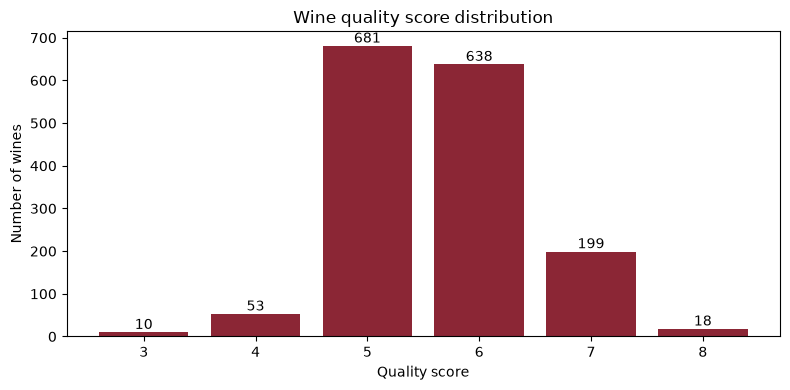

In [5]:
# Count wines at each observed quality score.
quality_counts = data["quality"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(quality_counts.index.astype(str), quality_counts.values, color="#8b2635")
ax.set(title="Wine quality score distribution", xlabel="Quality score", ylabel="Number of wines")
for index, count in enumerate(quality_counts.values):
    ax.text(index, count, str(count), ha="center", va="bottom")
fig.tight_layout()
plt.show()

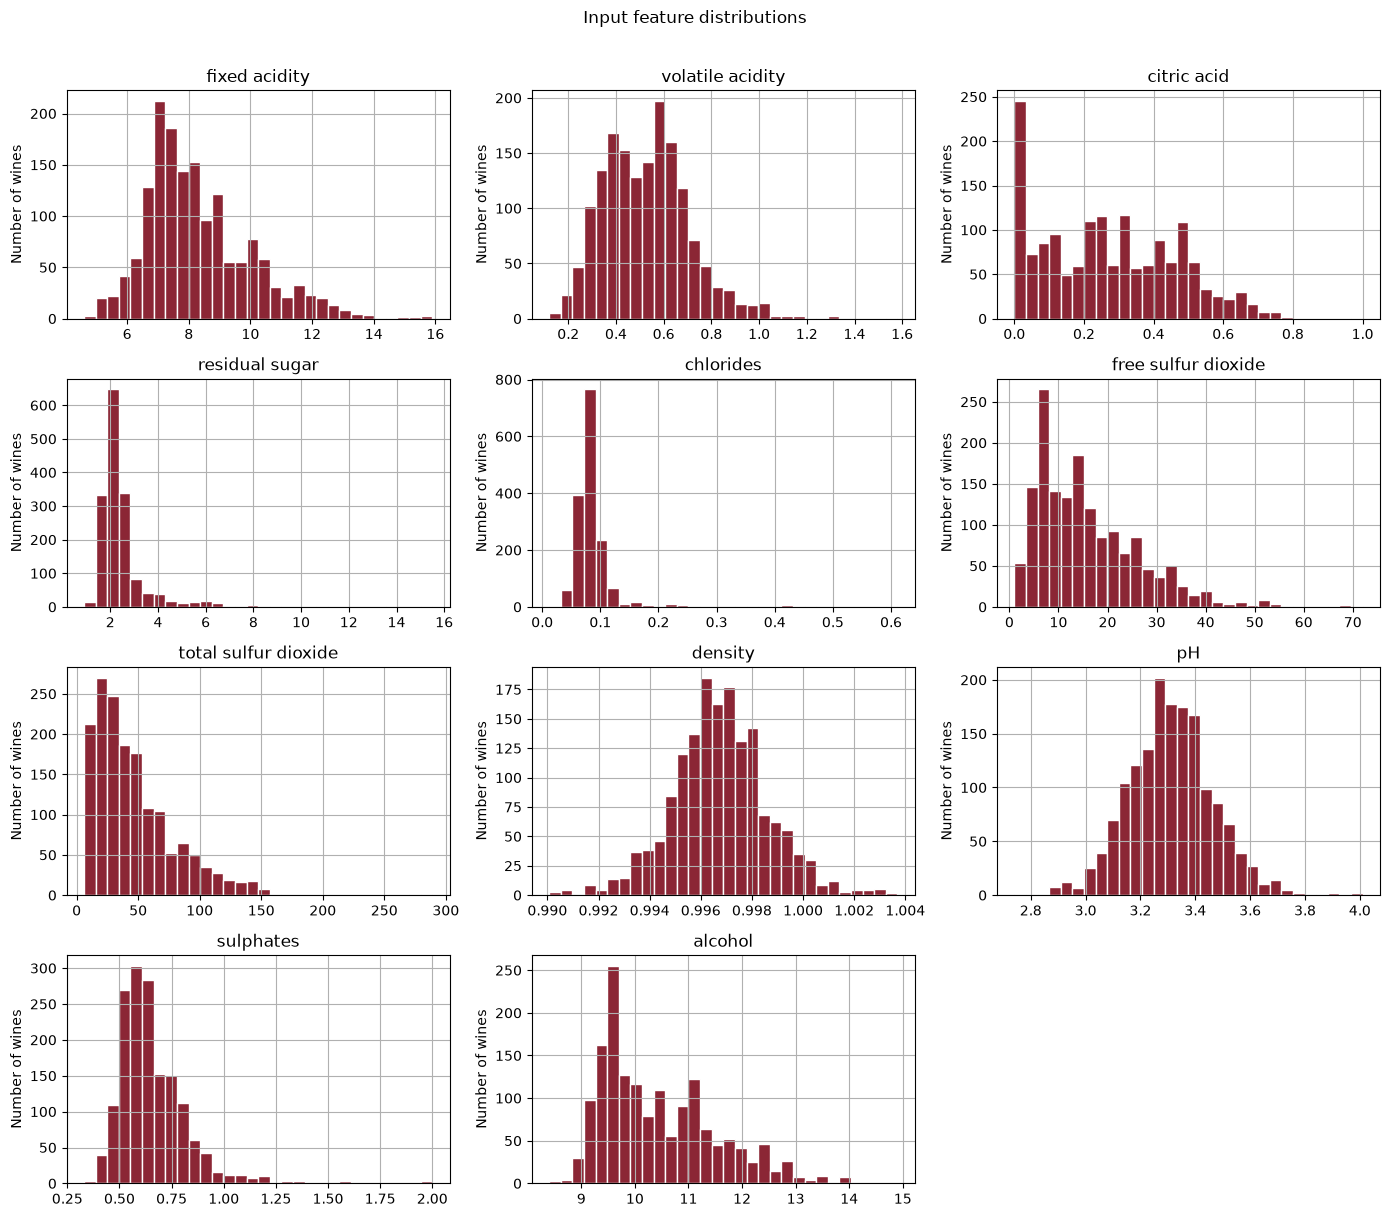

In [ ]:
# Feature Distributions
feature_columns = data.drop(columns="quality").select_dtypes(include=np.number).columns
axes = data[feature_columns].hist(figsize=(14, 12), bins=30, color="#8b2635", edgecolor="white")
for ax in axes.flat:
    ax.set_ylabel("Number of wines")
plt.suptitle("Input feature distributions", y=1.01)
plt.tight_layout()
plt.show()

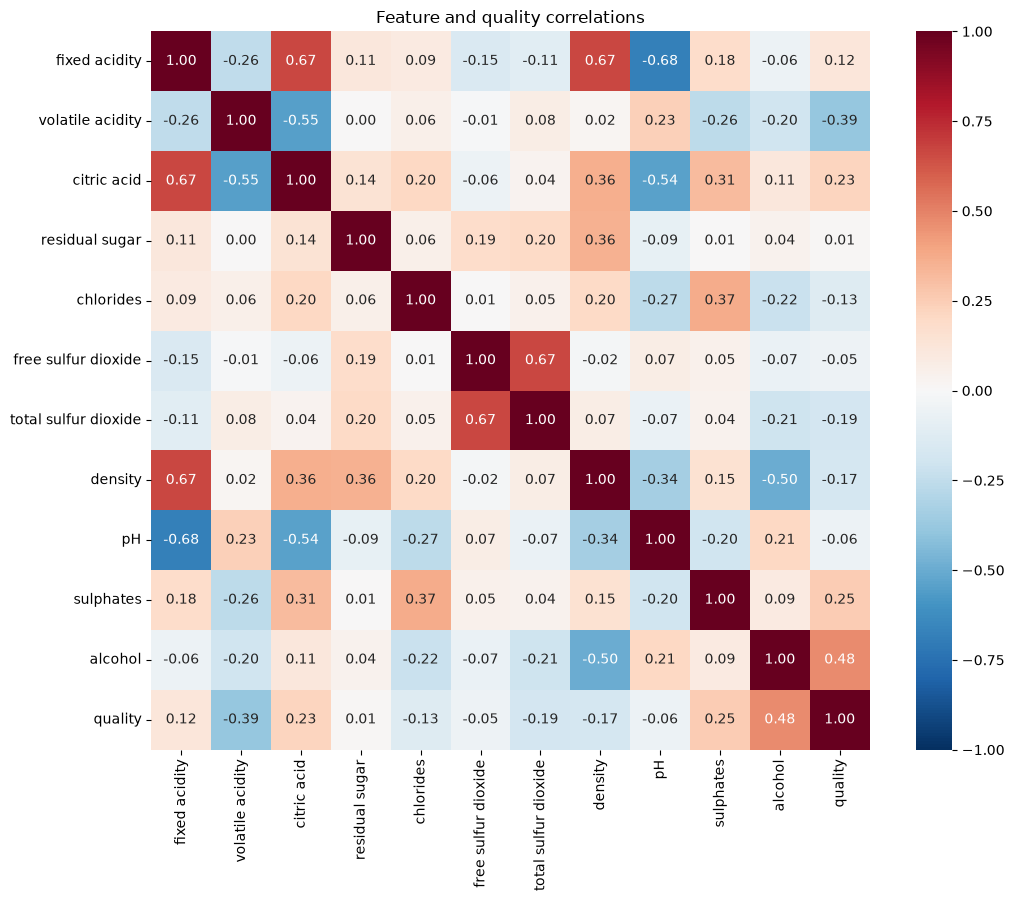

In [ ]:
# Correlations
correlations = data[[*feature_columns, "quality"]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Feature and quality correlations")
fig.tight_layout()
plt.show()

### Features across quality scores
Compare the distributions of the features most correlated with quality.

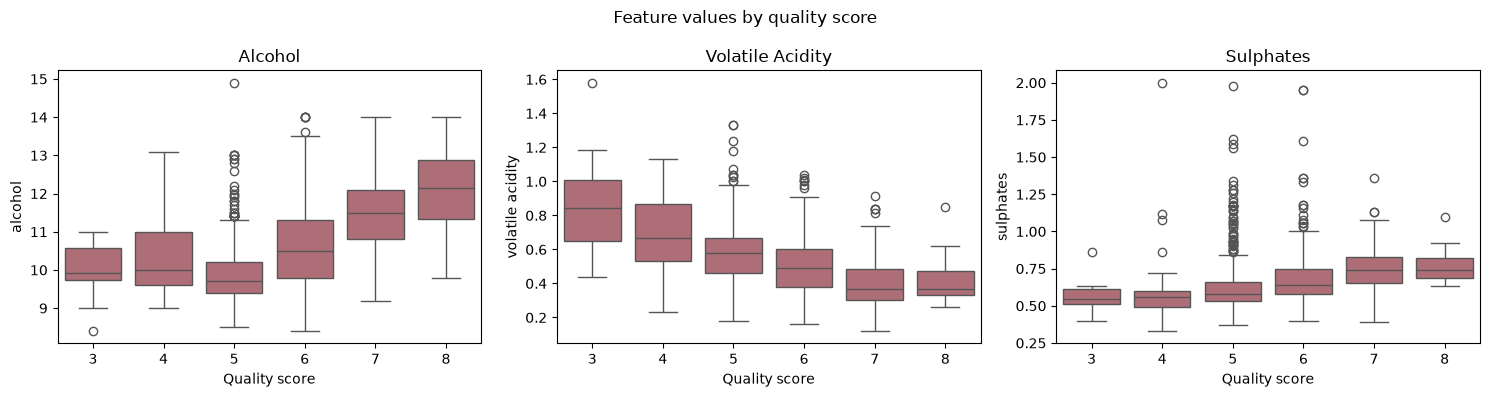

In [8]:
# Feature Accross Quality Scores
top_features = correlations["quality"].drop("quality").abs().nlargest(3).index
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, top_features):
    sns.boxplot(data=data, x="quality", y=feature, color="#b86370", ax=ax)
    ax.set(xlabel="Quality score", ylabel=feature, title=feature.title())
fig.suptitle("Feature values by quality score")
fig.tight_layout()
plt.show()

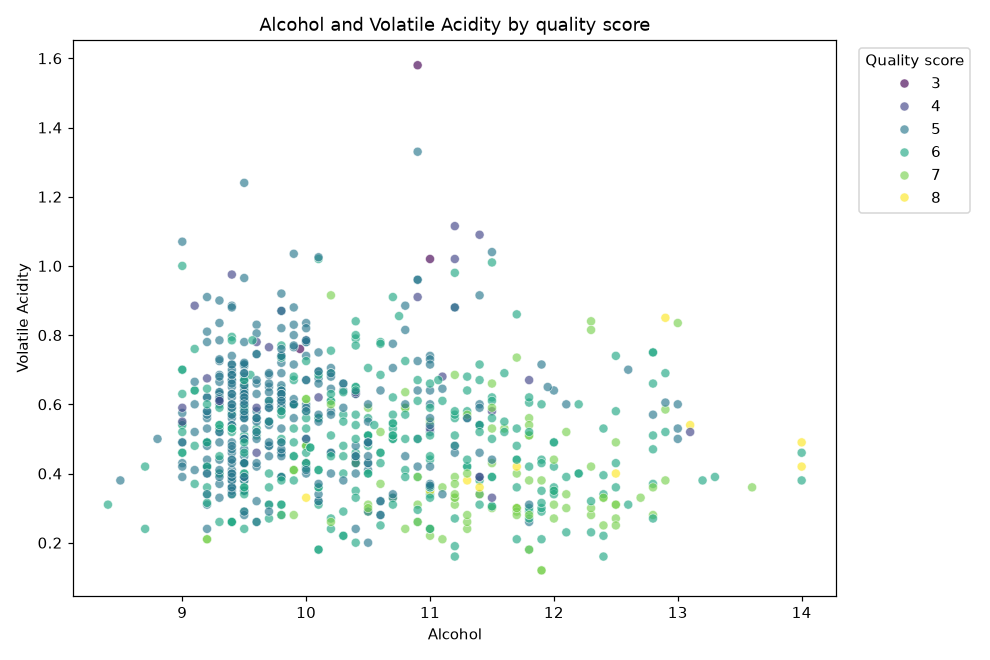

In [12]:
# Relationship Between Two Features
plot_data = data.sample(n=min(800, len(data)), random_state=42)
fig, ax = plt.subplots(figsize=(9, 6))

x = "alcohol"
y = "volatile acidity"

sns.scatterplot(data=plot_data, x=x, y=y, hue="quality",
                palette="viridis", alpha=0.65, s=35, ax=ax)
ax.set(title=f"{x.title()} and {y.title()} by quality score",
       xlabel=x.title(), ylabel=y.title())
ax.legend(title="Quality score", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()